# Bike Sharing 
This project explores how weather and calendar patterns relate to hourly bike rentals, comparing linear regression and a tree-based model to predict demand and understand where predictions fall short.

[Data source](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset)

In [32]:
import pandas as pd
import numpy as np

import datetime as dt
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
path = "/home/fra/Documenti/BIC/bike+sharing+dataset/"

bikes = pd.read_csv(path + "hour.csv", parse_dates=["dteday"])

In [3]:
bikes.head(10)

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0000,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0000,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0000,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0000,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0000,0,1,1
5,6,2011-01-01,1,0,1,5,0,6,0,2,0.24,0.2576,0.75,0.0896,0,1,1
6,7,2011-01-01,1,0,1,6,0,6,0,1,0.22,0.2727,0.80,0.0000,2,0,2
7,8,2011-01-01,1,0,1,7,0,6,0,1,0.20,0.2576,0.86,0.0000,1,2,3
8,9,2011-01-01,1,0,1,8,0,6,0,1,0.24,0.2879,0.75,0.0000,1,7,8
9,10,2011-01-01,1,0,1,9,0,6,0,1,0.32,0.3485,0.76,0.0000,8,6,14


In [4]:
bikes.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     17379 non-null  int64         
 1   dteday      17379 non-null  datetime64[us]
 2   season      17379 non-null  int64         
 3   yr          17379 non-null  int64         
 4   mnth        17379 non-null  int64         
 5   hr          17379 non-null  int64         
 6   holiday     17379 non-null  int64         
 7   weekday     17379 non-null  int64         
 8   workingday  17379 non-null  int64         
 9   weathersit  17379 non-null  int64         
 10  temp        17379 non-null  float64       
 11  atemp       17379 non-null  float64       
 12  hum         17379 non-null  float64       
 13  windspeed   17379 non-null  float64       
 14  casual      17379 non-null  int64         
 15  registered  17379 non-null  int64         
 16  cnt         17379 non-null  int64

In [5]:
# check for nulls and duplicates
bikes.isna().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [6]:
bikes.duplicated().sum()

np.int64(0)

In [7]:
# check for mistakes in the timestamp
bikes["timestamp"] = (
    bikes["dteday"] + pd.to_timedelta(bikes["hr"], unit="h")
)

bikes = bikes.sort_values("timestamp").reset_index(drop=True)

bikes["timestamp"].duplicated().sum()

np.int64(0)

In [8]:
bikes["timestamp"].agg(["min", "max"])

min   2011-01-01 00:00:00
max   2012-12-31 23:00:00
Name: timestamp, dtype: datetime64[us]

In [11]:
bikes.describe()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,timestamp
count,17379.0000,17379,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379
mean,8690.0000,2012-01-02 04:08:34.552045,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088,2012-01-02 15:41:22.858622
min,1.0000,2011-01-01 00:00:00,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2011-01-01 00:00:00
25%,4345.5000,2011-07-04 00:00:00,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000,2011-07-04 22:30:00
50%,8690.0000,2012-01-02 00:00:00,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000,2012-01-02 21:00:00
75%,13034.5000,2012-07-02 00:00:00,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000,2012-07-02 06:30:00
max,17379.0000,2012-12-31 00:00:00,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000,2012-12-31 23:00:00
std,5017.0295,NaN,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599,NaN


There are no evident outliers and no duplicates in the dataset. 

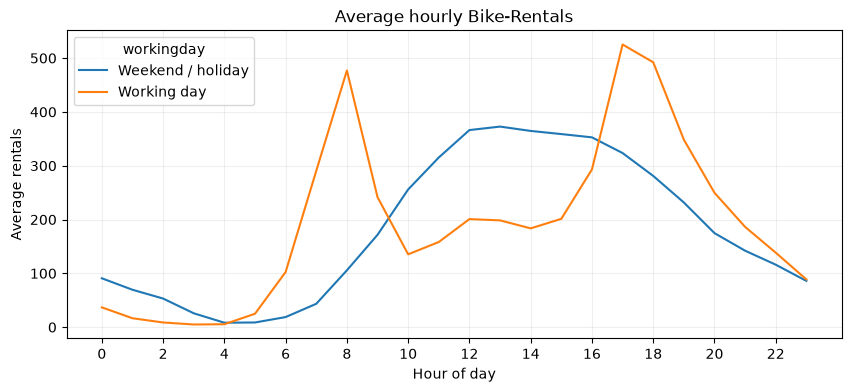

In [14]:
# check for hourly peaks
hourly_demand = (
    bikes.groupby(["hr", "workingday"])["cnt"]
    .mean()
    .unstack()
    .rename(columns={0: "Weekend / holiday", 1: "Working day"})
)

hourly_demand.plot(figsize=(10, 4))
plt.title("Average hourly Bike-Rentals")
plt.xlabel("Hour of day")
plt.ylabel("Average rentals")
plt.xticks(range(0, 24, 2))
plt.grid(alpha=0.2)
plt.show()

In working days we have two rental peaks, around 8AM and 5PM. On weekends and holidays, demand rises later and remains relatively high throughout the afternoon.

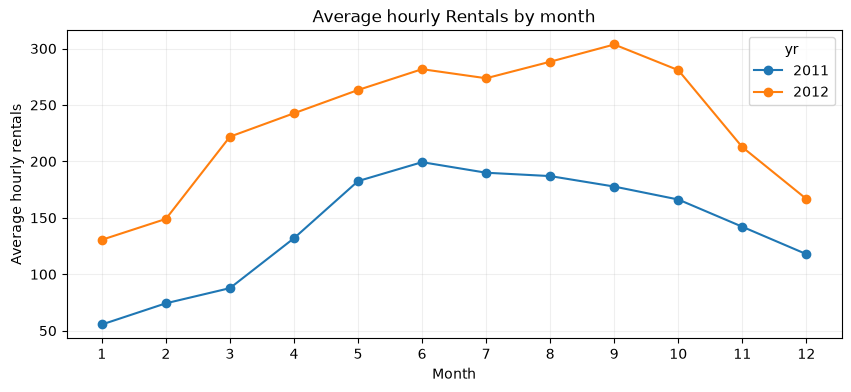

In [15]:
monthly_demand = (
    bikes.groupby(["mnth", "yr"])["cnt"]
    .mean()
    .unstack()
    .rename(columns={0: "2011", 1: "2012"})
)

monthly_demand.plot(marker="o", figsize=(10, 4))
plt.title("Average hourly Rentals by month")
plt.xlabel("Month")
plt.ylabel("Average hourly rentals")
plt.xticks(range(1, 13))
plt.grid(alpha=0.2)
plt.show()

Both years show similar seasonal patterns, with higher demand during warmer months. Average hourly rentals are consistently higher in 2012, suggesting growth in usage alongside seasonality.

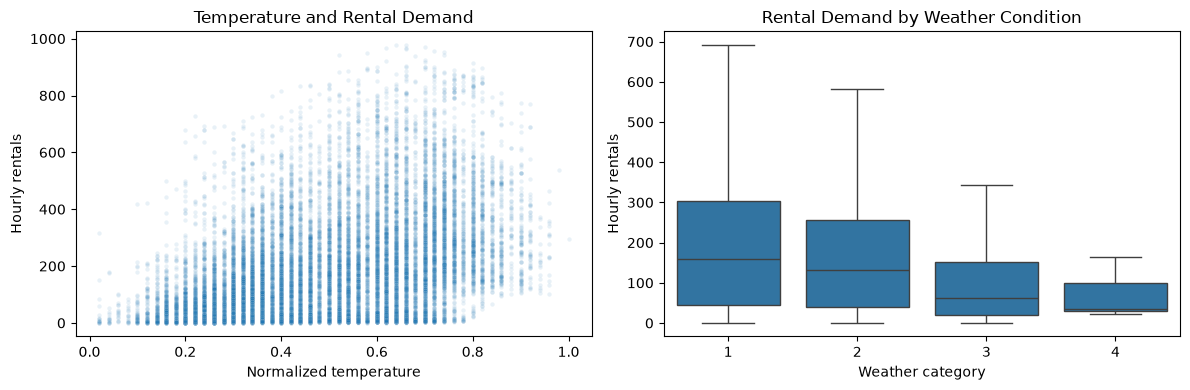

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.scatterplot(
    data=bikes, x="temp", y="cnt",
    alpha=0.1, s=10, ax=axes[0]
)
axes[0].set_title("Temperature and Rental Demand")
axes[0].set_xlabel("Normalized temperature")
axes[0].set_ylabel("Hourly rentals")

sns.boxplot(
    data=bikes, x="weathersit", y="cnt",
    showfliers=False, ax=axes[1]
)
axes[1].set_title("Rental Demand by Weather Condition")
axes[1].set_xlabel("Weather category")
axes[1].set_ylabel("Hourly rentals")

plt.tight_layout()
plt.show()

In [17]:
bikes["weathersit"].value_counts().sort_index()

weathersit
1    11413
2     4544
3     1419
4        3
Name: count, dtype: int64

Rental demand generally increases with temperature and variability remains substantial. Median demand is lower under less favorable weather conditions. Category 4 contains only three observations, so no reliable conclusion can be drawn for severe weather.

Since it is a prediction for the future and we have here the timestamp, we decide to train out model with all the data **before Oct 2012**, leaving the last three months for the successive test.

In [19]:
train = bikes.loc[bikes["timestamp"] < "2012-10-01"].copy()

test = bikes.loc[bikes["timestamp"] >= "2012-10-01"].copy()

In [27]:
categorical_features = ["hr", "mnth", "weekday", "workingday", "weathersit"]

numeric_features = ["temp", "hum", "windspeed"]

X = pd.get_dummies(
    bikes[categorical_features + numeric_features],
    columns=categorical_features,
    drop_first=True,
    dtype=int
)

y = bikes["cnt"]

In [28]:
X.head(10)

,temp,hum,windspeed,hr_1,hr_2,hr_3,hr_4,hr_5,hr_6,hr_7,...,weekday_1,weekday_2,weekday_3,weekday_4,weekday_5,weekday_6,workingday_1,weathersit_2,weathersit_3,weathersit_4
0,0.24,0.81,0.0000,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
1,0.22,0.80,0.0000,1,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
2,0.22,0.80,0.0000,0,1,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
3,0.24,0.75,0.0000,0,0,1,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
4,0.24,0.75,0.0000,0,0,0,1,0,0,0,...,0,0,0,0,0,1,0,0,0,0
5,0.24,0.75,0.0896,0,0,0,0,1,0,0,...,0,0,0,0,0,1,0,1,0,0
6,0.22,0.80,0.0000,0,0,0,0,0,1,0,...,0,0,0,0,0,1,0,0,0,0
7,0.20,0.86,0.0000,0,0,0,0,0,0,1,...,0,0,0,0,0,1,0,0,0,0
8,0.24,0.75,0.0000,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
9,0.32,0.76,0.0000,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0


In [29]:
train_mask = bikes["timestamp"] < "2012-10-01"

X_train = X.loc[train_mask].copy()
X_test = X.loc[~train_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[~train_mask].copy()

In [34]:
# initialize the model

model = LinearRegression()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [35]:
# Metrics

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²: {r2:.3f}")

MAE: 103.60
RMSE: 144.45
R²: 0.487


Linear regression achieved a test R² of 0.487, with a MAE of 103.60 rentals per hour and an RMSE of 144.45. It captures part of the variation in demand, but **substantial prediction errors** remain.

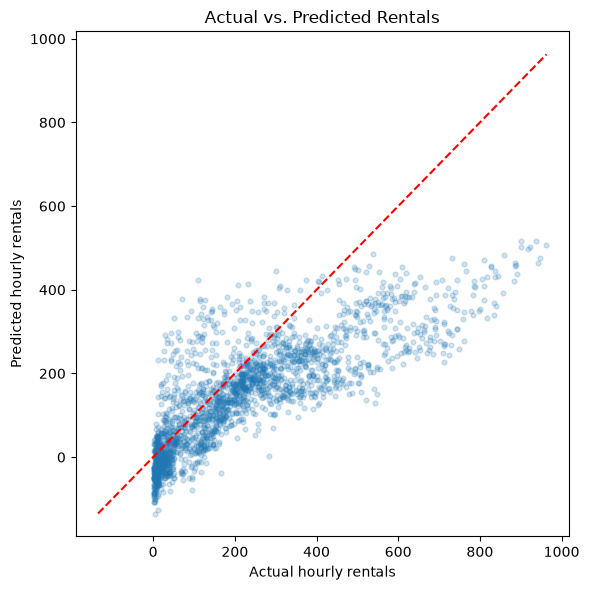

In [36]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.2, s=12)

limits = [
    min(y_test.min(), y_pred.min()),
    max(y_test.max(), y_pred.max())
]
plt.plot(limits, limits, "--", color="red")

plt.xlabel("Actual hourly rentals")
plt.ylabel("Predicted hourly rentals")
plt.title("Actual vs. Predicted Rentals")
plt.tight_layout()
plt.show()

Predictions underestimate high-demand hours and include some negative values at low demand levels. These patterns show limitations of this linear model in capturing the full range of hourly rentals.

In [37]:
# check for interactions

X_train_interaction = X_train.copy()
X_test_interaction = X_test.copy()

hour_columns = [col for col in X_train.columns if col.startswith("hr_")]

for df in [X_train_interaction, X_test_interaction]:
    for col in hour_columns:
        df[f"{col}_workingday"] = df[col] * df["workingday_1"]

In [39]:
interaction_model = LinearRegression()
interaction_model.fit(X_train_interaction, y_train)

y_pred_interaction = interaction_model.predict(X_test_interaction)

mae = mean_absolute_error(y_test, y_pred_interaction)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_interaction))
r2 = r2_score(y_test, y_pred_interaction)

print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²: {r2:.3f}")


MAE: 95.60
RMSE: 122.62
R²: 0.630


Allowing hourly patterns to differ between working and non-working days reduced MAE from 103.60 to 95.60 and RMSE from 144.45 to 122.62. R² increased to 0.630. This comparison is exploratory because the test results informed the model revision.

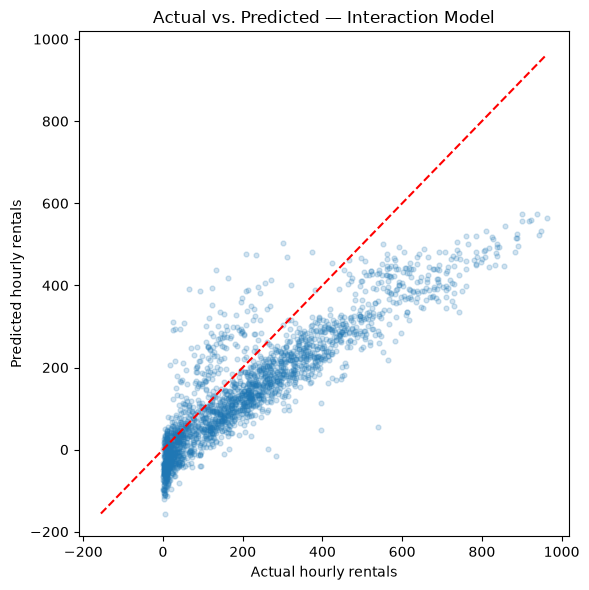

In [40]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_interaction, alpha=0.2, s=12)

limits = [
    min(y_test.min(), y_pred_interaction.min()),
    max(y_test.max(), y_pred_interaction.max())
]
plt.plot(limits, limits, "--", color="red")

plt.xlabel("Actual hourly rentals")
plt.ylabel("Predicted hourly rentals")
plt.title("Actual vs. Predicted — Interaction Model")
plt.tight_layout()
plt.show()

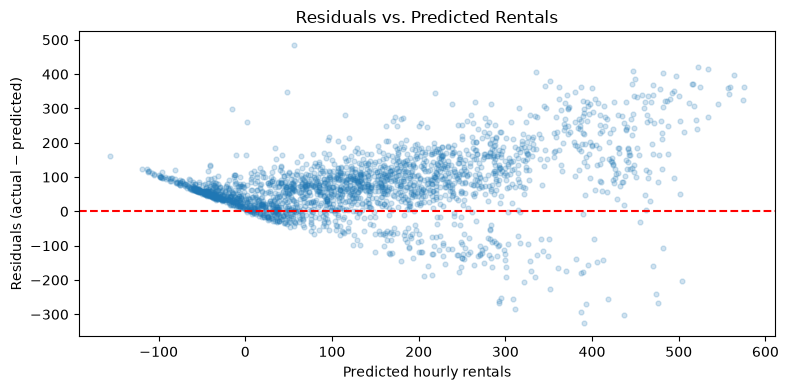

In [41]:
residuals = y_test - y_pred_interaction

plt.figure(figsize=(8, 4))
plt.scatter(y_pred_interaction, residuals, alpha=0.2, s=12)
plt.axhline(0, linestyle="--", color="red")

plt.xlabel("Predicted hourly rentals")
plt.ylabel("Residuals (actual − predicted)")
plt.title("Residuals vs. Predicted Rentals")
plt.tight_layout()
plt.show()

Despite improved overall metrics, the interaction model still underestimates peak demand and produces some negative predictions at low demand levels.

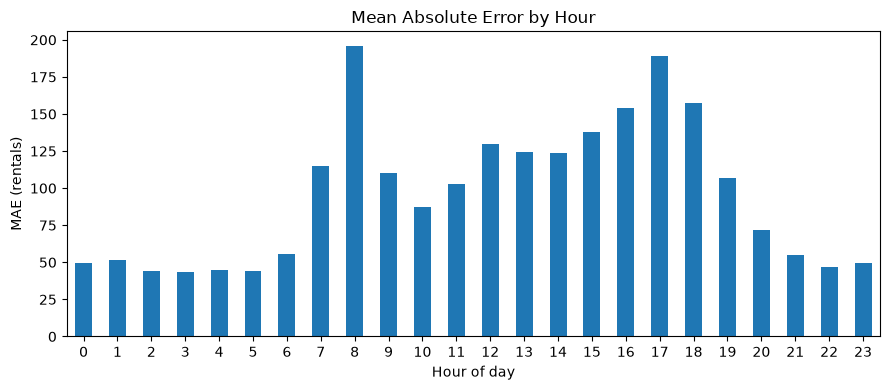

In [42]:
errors = pd.DataFrame({
    "hour": bikes.loc[X_test.index, "hr"],
    "absolute_error": np.abs(y_test - y_pred_interaction)
})

errors.groupby("hour")["absolute_error"].mean().plot.bar(
    figsize=(9, 4)
)

plt.title("Mean Absolute Error by Hour")
plt.xlabel("Hour of day")
plt.ylabel("MAE (rentals)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

MAE is highest around 8 AM and 5 PM, indicating difficulty predicting commuting peaks. Overnight errors are smaller in absolute terms, although rental demand is also lower.